In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("..")
from lens.raytrace import trace, best_spot, spot_at
from lens.design import R2_for

In [2]:
rng = np.random.default_rng(42)
print(rng.normal(29.5, 0.2))
print(rng.normal(29.5, 0.2, 5))

rng = np.random.default_rng(42)
print(rng.normal(29.5, 0.2))

29.560943415950888
[29.29200318 29.65009024 29.68811294 29.10979296 29.2395641 ]
29.560943415950888


In [3]:
x = rng.normal(0, 1, 100000)
print(np.mean(np.abs(x) < 1), np.mean(np.abs(x) < 2))

0.68173 0.9536


In [4]:
R1, t = 29.5, 6.0
R2 = R2_for(R1, t, 50)
design = [(0, R1, 1.5), (t, R2, 1.0)]
z_sensor, spot = best_spot(design)
print(R2, z_sensor, spot)

-152.77777777777774 51.3 0.06836939187099816


In [5]:
print(spot_at(design, z_sensor))

0.06836939187099816


In [6]:
rng = np.random.default_rng(42)
R1_made = rng.normal(R1, 0.2)
lens_made = [(0, R1_made, 1.5), (t, R2, 1.0)]
print(R1_made, spot_at(lens_made, z_sensor))

29.560943415950888 0.06902676368205972


In [7]:
rng = np.random.default_rng(42)
spots = []
for i in range(1000):
    R1_made = rng.normal(R1, 0.2)
    lens_made = [(0, R1_made, 1.5), (t, R2, 1.0)]
    spots.append(spot_at(lens_made, z_sensor))
spots = np.array(spots)
print(spots.mean(), spots.min(), spots.max())
print(np.mean(spots < 0.08))

0.07618820859778795 0.068358943208433 0.15052997382356084
0.763


0.07895879120963631 0.06742469571969446 0.1546579990217472
0.691


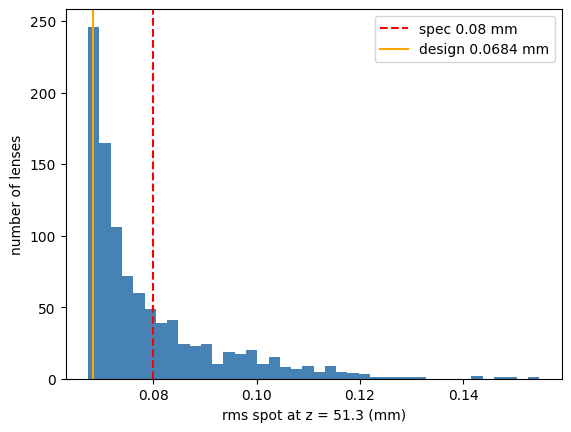

In [8]:
rng = np.random.default_rng(42)
spots = []
for i in range(1000):
    R1_made = rng.normal(R1, 0.2)
    R2_made = rng.normal(R2, 1.0)
    t_made = rng.normal(t, 0.1)
    n_made = rng.normal(1.5, 0.002)
    lens_made = [(0, R1_made, n_made), (t_made, R2_made, 1.0)]
    spots.append(spot_at(lens_made, z_sensor))
spots = np.array(spots)
print(spots.mean(), spots.min(), spots.max())
print(np.mean(spots < 0.08))

plt.hist(spots, bins = 40, color = "steelblue")
plt.axvline(0.08, color = "red", ls = "--", label = "spec 0.08 mm")
plt.axvline(spot, color = "orange", label = "design 0.0684 mm")
plt.xlabel("rms spot at z = 51.3 (mm)")
plt.ylabel("number of lenses")
plt.legend()
plt.show()

In [9]:
rng = np.random.default_rng(42)
spots = []
for i in range(1000):
    R1_made = rng.normal(R1, 0.2)
    lens_madeR1 = [(0, R1_made, 1.5), (t, R2, 1.0)]
    spots.append(spot_at(lens_madeR1, z_sensor))
spots = np.array(spots)
print(f"yield (when only R1 is random): {np.mean(spots < 0.08)}")

yield (when only R1 is random): 0.763


In [10]:
rng = np.random.default_rng(42)
spots = []
for i in range(1000):
    R2_made = rng.normal(R2, 1.0)
    lens_madeR2 = [(0, R1, 1.5), (t, R2_made, 1.0)]
    spots.append(spot_at(lens_madeR2, z_sensor))
spots = np.array(spots)
print(f"yield (when only R2 is random): {np.mean(spots < 0.08)}")

yield (when only R2 is random): 1.0


In [11]:
rng = np.random.default_rng(42)
spots = []
for i in range(1000):
    t_made = rng.normal(t, 0.1)
    lens_madet = [(0, R1, 1.5), (t_made, R2, 1.0)]
    spots.append(spot_at(lens_madet, z_sensor))
spots = np.array(spots)
print(f"yield (when only t is random): {np.mean(spots < 0.08)}")

yield (when only t is random): 1.0


In [12]:
rng = np.random.default_rng(42)
spots = []
for i in range(1000):
    n_made = rng.normal(1.5, 0.002)
    lens_maden = [(0, R1, n_made), (t, R2, 1.0)]
    spots.append(spot_at(lens_maden, z_sensor))
spots = np.array(spots)
print(f"yield (when only n is random): {np.mean(spots < 0.08)}")

yield (when only n is random): 0.933


In [13]:
# all four errors on, with normal sd
rng = np.random.default_rng(42)
spots = []
for i in range(1000):
    R1_made = rng.normal(R1, 0.2)
    R2_made = rng.normal(R2, 1.0)
    t_made = rng.normal(t, 0.1)
    n_made = rng.normal(1.5, 0.002)
    lens_made = [(0, R1_made, n_made), (t_made, R2_made, 1.0)]
    spots.append(spot_at(lens_made, z_sensor))
spots = np.array(spots)
print(f"yield (when sd is normal): {np.mean(spots < 0.08)}")


yield (when sd is normal): 0.691


In [14]:
# all four errors on, with halved sd
rng = np.random.default_rng(42)
spots = []
for i in range(1000):
    R1_made = rng.normal(R1, 0.1)
    R2_made = rng.normal(R2, 0.5)
    t_made = rng.normal(t, 0.05)
    n_made = rng.normal(1.5, 0.001)
    lens_made = [(0, R1_made, n_made), (t_made, R2_made, 1.0)]
    spots.append(spot_at(lens_made, z_sensor))
spots = np.array(spots)
print(f"yield (when sd is halved): {np.mean(spots < 0.08)}")


yield (when sd is halved): 0.952


In [15]:
# all four errors on, with doubled sd
rng = np.random.default_rng(42)
spots = []
for i in range(1000):
    R1_made = rng.normal(R1, 0.4)
    R2_made = rng.normal(R2, 2.0)
    t_made = rng.normal(t, 0.2)
    n_made = rng.normal(1.5, 0.004)
    lens_made = [(0, R1_made, n_made), (t_made, R2_made, 1.0)]
    spots.append(spot_at(lens_made, z_sensor))
spots = np.array(spots)
print(f"yield (when sd is doubled): {np.mean(spots < 0.08)}")


yield (when sd is doubled): 0.387


halving the errors takes it from about 7 in 10 lenses passing to 19 in 20. 

doubling them means most lenses fail.

tightening just R1 might do the trick though coz most of the yield is damaged by it. trying that down below.

In [16]:
# all four errors on, with only R1 sd halved
rng = np.random.default_rng(42)
spots = []
for i in range(1000):
    R1_made = rng.normal(R1, 0.1)
    R2_made = rng.normal(R2, 1.0)
    t_made = rng.normal(t, 0.1)
    n_made = rng.normal(1.5, 0.002)
    lens_made = [(0, R1_made, n_made), (t_made, R2_made, 1.0)]
    spots.append(spot_at(lens_made, z_sensor))
spots = np.array(spots)
print(f"yield (when sd for only R1 is halved): {np.mean(spots < 0.08)}")


yield (when sd for only R1 is halved): 0.835


In [17]:
# all four errors on, with seed 1
rng = np.random.default_rng(1)
spots = []
for i in range(1000):
    R1_made = rng.normal(R1, 0.2)
    R2_made = rng.normal(R2, 1.0)
    t_made = rng.normal(t, 0.1)
    n_made = rng.normal(1.5, 0.002)
    lens_made = [(0, R1_made, n_made), (t_made, R2_made, 1.0)]
    spots.append(spot_at(lens_made, z_sensor))
spots = np.array(spots)
print(f"yield (seed = 1): {np.mean(spots < 0.08)}")


yield (seed = 1): 0.65


In [18]:
# all four errors on, with seed 2
rng = np.random.default_rng(2)
spots = []
for i in range(1000):
    R1_made = rng.normal(R1, 0.2)
    R2_made = rng.normal(R2, 1.0)
    t_made = rng.normal(t, 0.1)
    n_made = rng.normal(1.5, 0.002)
    lens_made = [(0, R1_made, n_made), (t_made, R2_made, 1.0)]
    spots.append(spot_at(lens_made, z_sensor))
spots = np.array(spots)
print(f"yield (seed = 2): {np.mean(spots < 0.08)}")


yield (seed = 2): 0.655


In [19]:
# all four errors on, with seed 3
rng = np.random.default_rng(3)
spots = []
for i in range(1000):
    R1_made = rng.normal(R1, 0.2)
    R2_made = rng.normal(R2, 1.0)
    t_made = rng.normal(t, 0.1)
    n_made = rng.normal(1.5, 0.002)
    lens_made = [(0, R1_made, n_made), (t_made, R2_made, 1.0)]
    spots.append(spot_at(lens_made, z_sensor))
spots = np.array(spots)
print(f"yield (seed = 3): {np.mean(spots < 0.08)}")


yield (seed = 3): 0.682


In [20]:
def yield_for(sd_R1, sd_R2, sd_t, sd_n, refocus = False, seed = 42, N = 1000):
    rng = np.random.default_rng(seed)
    spots = []
    for i in range(N):
        R1_made = rng.normal(R1, sd_R1)
        R2_made = rng.normal(R2, sd_R2)
        t_made = rng.normal(t, sd_t)
        n_made = rng.normal(1.5, sd_n)
        lens_made = [(0, R1_made, n_made), (t_made, R2_made, 1.0)]
        if refocus:
            z_best, s = best_spot(lens_made)
        else:
            s = spot_at(lens_made, z_sensor)
        spots.append(s)
    spots = np.array(spots)
    return np.mean(spots < 0.08)

print(yield_for(0.2, 1.0, 0.1, 0.002))
print(yield_for(0.1, 1.0, 0.1, 0.002))

0.691
0.835


In [21]:
print(yield_for(0.2, 1.0, 0.1, 0.002, refocus = True))

1.0


[0.691 0.757 0.835 0.875 0.903 0.92 ]


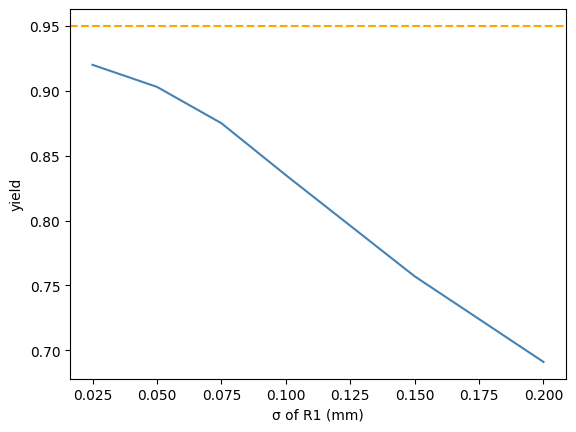

In [22]:
R1_diff_yields = []
R1_sds = [0.2, 0.15, 0.1, 0.075, 0.05, 0.025]
for R1_sd in R1_sds:
    y = yield_for(R1_sd, 1.0, 0.1, 0.002)
    R1_diff_yields.append(y)
R1_diff_yields = np.array(R1_diff_yields)
print(R1_diff_yields)
plt.plot(R1_sds, R1_diff_yields, color = "steelblue")
plt.axhline(0.95, ls = "--", color = "orange")
plt.xlabel("σ of R1 (mm)")
plt.ylabel("yield")
plt.show()

it never reaches 95%. tightening R1 helps a lot at first (R1 is the most sensitive), but the curve flattens around 92%. that’s because n still fails about 7% of lenses on its own, and tightening R1 can’t fix that.

In [23]:
print(yield_for(0.025, 1.0, 0.1, 0.001))

0.997


we can achieve 95+% yield just by adjusting the errors of R1 and n.

now to find the loosest combination by adjusting R1 errors values.

In [24]:
for R1_sd in [0.1, 0.075, 0.05]:
    print(R1_sd, yield_for(R1_sd, 1.0, 0.1, 0.001))

0.1 0.935
0.075 0.977
0.05 0.99


we can achieve 95+% yield by dropping R1 error rate to 0.075 and halving the error rate of the refractive index 'n' - which is the cheapest option.

In [25]:
print(yield_for(0.4, 2.0, 0.2, 0.004, refocus = True)) # doubled
print(yield_for(0.6, 3.0, 0.3, 0.006, refocus = True)) # tripled

1.0
1.0


so the lens companies should really be investing in the camera's ability to refocus.

50.2 52.400000000000006
[50.65 52.  ]


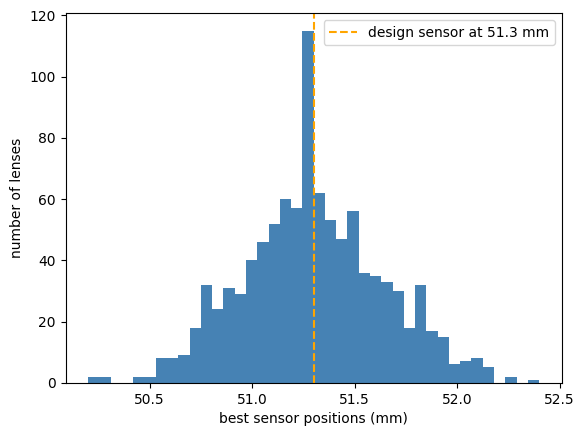

In [26]:
rng = np.random.default_rng(42)
z_bests = []
for i in range (1000):
    R1_made = rng.normal(R1, 0.2)
    R2_made = rng.normal(R2, 1.0)
    t_made = rng.normal(t, 0.1)
    n_made = rng.normal(1.5, 0.002)
    lens_made = [(0, R1_made, n_made), (t_made, R2_made, 1.0)]
    z_best, s = best_spot(lens_made)
    z_bests.append(z_best)
z_bests = np.array(z_bests)
print(z_bests.min(), z_bests.max())
print(np.percentile(z_bests, [2.5, 97.5]))
plt.hist(z_bests, bins = 40, color = "steelblue")
plt.axvline(51.3, ls = "--", color = "orange", label = "design sensor at 51.3 mm")
plt.xlabel("best sensor positions (mm)")
plt.ylabel("number of lenses")
plt.legend()
plt.show()

the focus mechanism needs to move 0.65 mm  to the left and 0.7 mm to the right to cover 95% of the lenses.